# Evaluating Data Efficiency in Human Action Recognition Using Pose-Based Features and Classical Machine Learning

## Project Overview

This project investigates the effect of labelled training-data quantity on human action recognition performance using pose-based features and classical machine learning algorithms.

The Penn Action dataset is used to extract movement and exploratory pose-geometry features from human pose annotations. Logistic Regression and Random Forest classifiers are trained and evaluated using different quantities of labelled training data.

## Research Question

How does reducing the amount of labelled training data affect human action recognition performance?

## Objectives

1. Explore a human action recognition dataset containing pose annotations.
2. Extract movement-based and exploratory pose-geometry features.
3. Develop classification models using Logistic Regression and Random Forest.
4. Compare model performance using Accuracy and Macro F1.
5. Investigate model performance at different labelled training-data fractions.

## Tools and Technologies

- Python
- Google Colab
- NumPy and Pandas
- Matplotlib
- SciPy
- Scikit-learn
- Penn Action dataset

## 1. Environment Setup and Libraries

Install the required packages, import libraries, and create working folders.


In [1]:
!pip install numpy pandas matplotlib scikit-learn scipy opencv-python

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from scipy.io import loadmat

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
folders = [
    "data",
    "notebooks",
    "results",
    "models",
    "reports"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project structure created successfully!")

Project structure created successfully!


## 2. Dataset Acquisition and Inspection

The following cells check available storage, download and extract Penn Action, inspect its directory structure, and examine its annotations and predefined split.


In [4]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   89M  108G   1% /


In [5]:
import os

os.makedirs("/content/data", exist_ok=True)

!wget -O /content/data/Penn_Action.tar.gz \
https://www.cis.upenn.edu/~kostas/Penn_Action.tar.gz

--2026-11-08 02:26:12--  https://www.cis.upenn.edu/~kostas/Penn_Action.tar.gz
Resolving www.cis.upenn.edu (www.cis.upenn.edu)... 158.130.69.163, 2607:f470:8:64:5ea5::d
Connecting to www.cis.upenn.edu (www.cis.upenn.edu)|158.130.69.163|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3235203923 (3.0G) [application/x-gzip]
Saving to: ‘/content/data/Penn_Action.tar.gz’

/content/data/Penn_ 100%[===================>]   3.01G  15.5MB/s    in 3m 14s  

2026-11-08 02:29:27 (15.9 MB/s) - ‘/content/data/Penn_Action.tar.gz’ saved [3235203923/3235203923]



In [6]:
import os

file_path = "/content/data/Penn_Action.tar.gz"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size (GB):", round(
        os.path.getsize(file_path) / (1024**3), 2
    ))

File exists: True
File size (GB): 3.01


In [7]:
import tarfile
import os

archive_path = "/content/data/Penn_Action.tar.gz"
extract_path = "/content/data/Penn_Action"

os.makedirs(extract_path, exist_ok=True)

with tarfile.open(archive_path, "r:gz") as tar:
    tar.extractall(path=extract_path)

print("Dataset extracted successfully!")

/tmp/ipykernel_999/807077447.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Dataset extracted successfully!


In [8]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:5]:
            print("  " * (level + 1) + file)

Penn_Action/
  Penn_Action/
    README
    tools/
      visualize.m
      CreatePointLightDisplay.m
    labels/
      0029.mat
      0705.mat
      1565.mat
      1276.mat
      1830.mat
    frames/


In [9]:
import os
from scipy.io import loadmat

labels_path = "/content/data/Penn_Action/Penn_Action/labels"

mat_files = [f for f in os.listdir(labels_path) if f.endswith(".mat")]

print("Total annotation files:", len(mat_files))

sample_file = os.path.join(labels_path, mat_files[0])

data = loadmat(sample_file)

print("\nAvailable annotation fields:")

for key, value in data.items():
    if not key.startswith("__"):
        print(key, type(value), getattr(value, "shape", None))

Total annotation files: 2326

Available annotation fields:
action <class 'numpy.ndarray'> (1,)
pose <class 'numpy.ndarray'> (1,)
x <class 'numpy.ndarray'> (116, 13)
y <class 'numpy.ndarray'> (116, 13)
visibility <class 'numpy.ndarray'> (116, 13)
train <class 'numpy.ndarray'> (1, 1)
bbox <class 'numpy.ndarray'> (116, 4)
dimensions <class 'numpy.ndarray'> (1, 3)
nframes <class 'numpy.ndarray'> (1, 1)


In [10]:
import numpy as np
from scipy.io import loadmat
import os

labels_path = "/content/data/Penn_Action/Penn_Action/labels"

sample_file = os.path.join(labels_path, mat_files[0])
data = loadmat(sample_file)

print("Sample file:", mat_files[0])

print("\nAction:", data["action"].squeeze())
print("Pose:", data["pose"].squeeze())
print("Training indicator:", data["train"].squeeze())
print("Number of frames:", data["nframes"].squeeze())
print("Dimensions:", data["dimensions"].squeeze())

print("\nFirst frame X coordinates:")
print(data["x"][0])

print("\nFirst frame Y coordinates:")
print(data["y"][0])

print("\nFirst frame visibility:")
print(data["visibility"][0])

Sample file: 0029.mat

Action: baseball_pitch
Pose: back
Training indicator: -1
Number of frames: 116
Dimensions: [360 480 116]

First frame X coordinates:
[407.25 426.75 381.75 417.   371.25 423.75 412.5  409.5  382.5  411.
 380.25 405.   379.5 ]

First frame Y coordinates:
[108.75 141.75 141.   184.5  174.75 133.5  141.75 210.   210.   261.
 261.   308.25 309.  ]

First frame visibility:
[1 1 1 0 1 0 0 1 1 1 1 1 1]


In [11]:
readme_path = "/content/data/Penn_Action/Penn_Action/README"

with open(readme_path, "r") as file:
    readme = file.read()

print(readme)

                     Penn Action Dataset


------------------------------------------------------------
                          Reference
------------------------------------------------------------
If you use our dataset, please cite the following paper:

Weiyu Zhang, Menglong Zhu, Kosta Derpanis,  "From Actemes 
to Action: A Strongly-supervised Representation for Detailed 
Action Understanding" International Conference on Computer 
Vision (ICCV). Dec 2013.

------------------------------------------------------------
                       Dataset Content
------------------------------------------------------------
Penn Action Dataset contains 2326 video sequences of 15 
different actions and human joint annotation for each 
sequence. The dataset is organized in the following format:

/frames  ( all image sequences )
   /0001 
      000001.jpg
      000002.jpg
      ...
   /0002
    ...
/labels  ( all annotations )
    0001.mat
    0002.mat
    ...
/tools   ( visualization scripts 

In [12]:
import numpy as np
import os
from scipy.io import loadmat

labels_path = "/content/data/Penn_Action/Penn_Action/labels"

train_values = []

for filename in os.listdir(labels_path):

    if filename.endswith(".mat"):

        data = loadmat(
            os.path.join(labels_path, filename)
        )

        value = int(data["train"].squeeze())
        train_values.append(value)

unique, counts = np.unique(
    train_values,
    return_counts=True
)

for value, count in zip(unique, counts):
    print("Train value:", value, "| Count:", count)

print("Total sequences:", len(train_values))

Train value: -1 | Count: 1068
Train value: 1 | Count: 1258
Total sequences: 2326


In [13]:
import os
import numpy as np
import pandas as pd
from scipy.io import loadmat

labels_path = "/content/data/Penn_Action/Penn_Action/labels"

records = []

for filename in os.listdir(labels_path):
    if filename.endswith(".mat"):

        data = loadmat(os.path.join(labels_path, filename))

        action = data["action"].squeeze().item()

        if isinstance(action, bytes):
            action = action.decode("utf-8")

        train_value = int(data["train"].squeeze())

        records.append({
            "video": filename.replace(".mat", ""),
            "action": str(action),
            "split": "train" if train_value == 1 else "test",
            "frames": int(data["nframes"].squeeze())
        })

df = pd.DataFrame(records)

print("Dataset shape:", df.shape)
print("\nAction classes:")
print(df["action"].nunique())

print("\nSequences per action:")
print(df["action"].value_counts())

print("\nTraining and testing distribution:")
print(pd.crosstab(df["action"], df["split"]))

Dataset shape: (2326, 4)

Action classes:
15

Sequences per action:
action
squat              231
bowl               220
pushup             211
pullup             199
tennis_serve       186
baseball_swing     173
baseball_pitch     167
golf_swing         166
tennis_forehand    157
bench_press        140
jumping_jacks      112
situp              100
strum_guitar        94
clean_and_jerk      88
jump_rope           82
Name: count, dtype: int64

Training and testing distribution:
split            test  train
action                      
baseball_pitch     63    104
baseball_swing     58    115
bench_press        71     69
bowl               85    135
clean_and_jerk     45     43
golf_swing         77     89
jump_rope          42     40
jumping_jacks      56     56
pullup            101     98
pushup            107    104
situp              50     50
squat             117    114
strum_guitar       48     46
tennis_forehand    77     80
tennis_serve       71    115


In [14]:
import os
from scipy.io import loadmat

labels_path = "/content/data/Penn_Action/Penn_Action/labels"

data = loadmat(os.path.join(labels_path, "1712.mat"))

print("X shape:", data["x"].shape)
print("Y shape:", data["y"].shape)
print("Visibility shape:", data["visibility"].shape)

print("\nFirst frame X:")
print(data["x"][0])

print("\nFirst frame Y:")
print(data["y"][0])

print("\nVisibility values:")
print(data["visibility"][0])

X shape: (75, 13)
Y shape: (75, 13)
Visibility shape: (75, 13)

First frame X:
[254.66666667 290.         240.66666667 331.33333333   0.66666667
 305.33333333   0.66666667 288.         232.         280.66666667
 233.33333333 286.66666667 229.33333333]

First frame Y:
[  6.           8.           9.33333333   8.           0.66666667
   7.33333333   0.66666667  78.          84.         151.33333333
 156.         236.66666667 229.33333333]

Visibility values:
[0 0 0 0 0 0 0 1 1 1 1 1 1]


## 3. Research Methodology

### Dataset and split
Penn Action contains 2,326 annotated video sequences across 15 action categories. The supplied training/testing indicator is preserved. The final feature table contains 2,325 sequences because one sequence has no usable visible-joint observations for movement extraction.

### Movement features
For each sequence, Euclidean displacement is calculated between consecutive frames for joints annotated in both frames. Four sequence-level statistics are extracted: mean, standard deviation, maximum, and minimum movement.

### Exploratory pose-geometry features
Coordinates are normalised relative to the supplied bounding box. The final model uses mean and standard deviation of distances between consecutive annotation columns. The anatomical ordering of the columns has not been verified, so these are treated as exploratory annotation-column geometry features, not named anatomical measurements. Angle features are excluded from modelling.

### Models and evaluation
Logistic Regression and Random Forest are evaluated on the official test set. Accuracy and Macro F1 are reported. Missing geometry values are median-imputed within model pipelines; Logistic Regression also uses StandardScaler.

### Data-efficiency experiment
Stratified subsets containing 10%, 25%, 50%, 75%, and 100% of the training data are evaluated using three random seeds. The official test set remains fixed. Preprocessing is fitted within each training run.


## 4. Movement Feature Extraction

Inspect one annotation sequence, define the movement-feature function, and create the sequence-level movement feature table. One sequence with no valid movement observations is excluded.


In [15]:
def extract_movement_features(data):

    x = data["x"].astype(float)
    y = data["y"].astype(float)
    visibility = data["visibility"].astype(bool)

    dx = np.diff(x, axis=0)
    dy = np.diff(y, axis=0)

    movement = np.sqrt(dx**2 + dy**2)

    valid = visibility[:-1] & visibility[1:]
    valid_movement = movement[valid]

    if valid_movement.size == 0:
        return {
            "mean_movement": np.nan,
            "std_movement": np.nan,
            "max_movement": np.nan,
            "min_movement": np.nan
        }

    return {
        "mean_movement": float(np.mean(valid_movement)),
        "std_movement": float(np.std(valid_movement)),
        "max_movement": float(np.max(valid_movement)),
        "min_movement": float(np.min(valid_movement))
    }

In [16]:
sample = loadmat(
    "/content/data/Penn_Action/Penn_Action/labels/1712.mat"
)

print(extract_movement_features(sample))

{'mean_movement': 2.403012374036045, 'std_movement': 2.09947512808328, 'max_movement': 12.238373167123871, 'min_movement': 0.0}


In [17]:
records = []

for filename in os.listdir(labels_path):

    if not filename.endswith(".mat"):
        continue

    data = loadmat(os.path.join(labels_path, filename))

    action = data["action"].squeeze().item()

    if isinstance(action, bytes):
        action = action.decode("utf-8")

    train_value = int(data["train"].squeeze())

    features = extract_movement_features(data)

    if np.isnan(features["mean_movement"]):
        continue

    records.append({
        "video": filename.replace(".mat", ""),
        "action": str(action),
        "split": "train" if train_value == 1 else "test",
        **features
    })

feature_df = pd.DataFrame(records)

print("Clean dataset shape:", feature_df.shape)
print("\nMissing values:")
print(feature_df.isnull().sum())

print("\nSplit distribution:")
print(feature_df["split"].value_counts())

Clean dataset shape: (2325, 7)

Missing values:
video            0
action           0
split            0
mean_movement    0
std_movement     0
max_movement     0
min_movement     0
dtype: int64

Split distribution:
split
train    1257
test     1068
Name: count, dtype: int64


In [18]:
feature_df.to_csv(
    "/content/data/penn_action_movement_features.csv",
    index=False
)

## 5. Pose-Geometry Feature Extraction

Define the angle helper used during exploration, extract bounding-box-normalised adjacent-column distances, and build the combined feature dataset. Angle summaries are retained for exploratory inspection but are not used in the classifiers.


In [19]:
def joint_angle(A, B, C):

    A = np.array(A)
    B = np.array(B)
    C = np.array(C)

    BA = A - B
    BC = C - B

    denominator = np.linalg.norm(BA) * np.linalg.norm(BC)

    if denominator == 0:
        return np.nan

    cosine = np.dot(BA, BC) / denominator

    # Prevent numerical errors
    cosine = np.clip(cosine, -1.0, 1.0)

    angle = np.degrees(np.arccos(cosine))

    return angle

In [20]:
def extract_geometry_features(data):

    x = data["x"].astype(float)
    y = data["y"].astype(float)
    visibility = data["visibility"].astype(bool)
    bbox = data["bbox"].astype(float)

    nframes = min(
        len(x), len(y), len(visibility), len(bbox)
    )

    x = x[:nframes]
    y = y[:nframes]
    visibility = visibility[:nframes]
    bbox = bbox[:nframes]

    distances = []
    angles = []

    for frame in range(nframes):

        x_min, y_min, x_max, y_max = bbox[frame]

        width = x_max - x_min
        height = y_max - y_min

        if width <= 0 or height <= 0:
            continue

        xr = (x[frame] - x_min) / width
        yr = (y[frame] - y_min) / height

        for j in range(12):
            if visibility[frame, j] and visibility[frame, j+1]:
                p1 = np.array([xr[j], yr[j]])
                p2 = np.array([xr[j+1], yr[j+1]])
                distances.append(np.linalg.norm(p2-p1))

        for j in range(1, 12):
            if (visibility[frame, j-1] and
                visibility[frame, j] and
                visibility[frame, j+1]):

                A = [xr[j-1], yr[j-1]]
                B = [xr[j], yr[j]]
                C = [xr[j+1], yr[j+1]]

                angle = joint_angle(A, B, C)

                if np.isfinite(angle):
                    angles.append(angle)

    return {
        "mean_joint_distance": np.mean(distances) if distances else np.nan,
        "std_joint_distance": np.std(distances) if distances else np.nan,
        "mean_pose_angle": np.mean(angles) if angles else np.nan,
        "std_pose_angle": np.std(angles) if angles else np.nan
    }

In [21]:
combined_records = []

for filename in os.listdir(labels_path):

    if not filename.endswith(".mat"):
        continue

    data = loadmat(os.path.join(labels_path, filename))

    action = data["action"].squeeze().item()

    if isinstance(action, bytes):
        action = action.decode("utf-8")

    train_value = int(data["train"].squeeze())

    movement_features = extract_movement_features(data)
    geometry_features = extract_geometry_features(data)

    if np.isnan(movement_features["mean_movement"]):
        continue

    record = {
        "video": filename.replace(".mat", ""),
        "action": str(action),
        "split": "train" if train_value == 1 else "test",
        **movement_features,
        **geometry_features
    }

    combined_records.append(record)

combined_df = pd.DataFrame(combined_records)

print("Combined dataset created!")
print("Shape:", combined_df.shape)

Combined dataset created!
Shape: (2325, 11)


In [22]:
print("Missing values:")
print(combined_df.isnull().sum())

print("\nTraining and testing:")
print(combined_df["split"].value_counts())

print("\nFirst five rows:")
print(combined_df.head())

Missing values:
video                   0
action                  0
split                   0
mean_movement           0
std_movement            0
max_movement            0
min_movement            0
mean_joint_distance    25
std_joint_distance     25
mean_pose_angle        70
std_pose_angle         70
dtype: int64

Training and testing:
split
train    1257
test     1068
Name: count, dtype: int64

First five rows:
  video          action  split  mean_movement  std_movement  max_movement  \
0  0029  baseball_pitch   test       2.843710      3.751206     55.974324   
1  0705  clean_and_jerk   test       1.956407      1.884635     14.773287   
2  1565           situp   test       2.852418      3.153794     16.500000   
3  1276          pullup   test       1.870631      1.603522      8.000000   
4  1830           squat  train       1.406804      1.379983      8.944272   

   min_movement  mean_joint_distance  std_joint_distance  mean_pose_angle  \
0           0.0             0.440373        

## 6. Missing-Value Inspection and Data Preparation

Inspect missing geometry features and preserve the official training/testing partition. Imputation is performed inside each model pipeline to avoid fitting imputation values on the test data.


In [23]:
missing_geometry = combined_df[
    combined_df[
        ["mean_joint_distance", "mean_pose_angle"]
    ].isnull().any(axis=1)
]

print("Videos with missing geometry:",
      len(missing_geometry))

print("\nAffected video IDs and actions:")
print(
    missing_geometry[
        ["video", "action", "split",
         "mean_joint_distance", "mean_pose_angle"]
    ].to_string(index=False)
)

Videos with missing geometry: 70

Affected video IDs and actions:
video         action split  mean_joint_distance  mean_pose_angle
 0711 clean_and_jerk train                  NaN              NaN
 1882          squat  test                  NaN              NaN
 1406         pushup  test                  NaN              NaN
 1706          squat  test             0.127001              NaN
 1353         pushup  test             0.304815              NaN
 1650          situp train             0.541791              NaN
 1667          squat train             0.125509              NaN
 1361         pushup  test                  NaN              NaN
 1135  jumping_jacks  test             0.235220              NaN
 1485         pushup train             0.186642              NaN
 1505         pushup  test             0.149953              NaN
 1690          squat  test                  NaN              NaN
 1716          squat train             0.147755              NaN
 1866          squat  te

In [24]:
missing_distance = combined_df[
    combined_df["mean_joint_distance"].isna()
]

print("Videos without distance features:",
      len(missing_distance))

print("\nAffected actions:")
print(missing_distance["action"].value_counts())

print("\nTraining/testing distribution:")
print(missing_distance["split"].value_counts())

Videos without distance features: 25

Affected actions:
action
squat             10
pushup             9
clean_and_jerk     2
jump_rope          2
pullup             2
Name: count, dtype: int64

Training/testing distribution:
split
test     16
train     9
Name: count, dtype: int64


In [25]:
missing_summary = (
    combined_df.assign(
        distance_missing=combined_df["mean_joint_distance"].isna()
    )
    .groupby("action")
    .agg(
        total_videos=("video", "count"),
        missing_distance=("distance_missing", "sum")
    )
)

missing_summary["missing_percentage"] = (
    missing_summary["missing_distance"] /
    missing_summary["total_videos"] * 100
)

print(missing_summary.sort_values(
    "missing_percentage",
    ascending=False
))

                 total_videos  missing_distance  missing_percentage
action                                                             
squat                     231                10            4.329004
pushup                    210                 9            4.285714
jump_rope                  82                 2            2.439024
clean_and_jerk             88                 2            2.272727
pullup                    199                 2            1.005025
bench_press               140                 0            0.000000
baseball_pitch            167                 0            0.000000
golf_swing                166                 0            0.000000
bowl                      220                 0            0.000000
baseball_swing            173                 0            0.000000
jumping_jacks             112                 0            0.000000
situp                     100                 0            0.000000
strum_guitar               94                 0 

In [26]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
from sklearn.pipeline import Pipeline

# Experiment A: Movement features
movement_columns = [
    "mean_movement",
    "std_movement",
    "max_movement",
    "min_movement"
]

# Experiment B: Movement + geometry
enhanced_columns = movement_columns + [
    "mean_joint_distance",
    "std_joint_distance"
]

# Preserve official split
train_df = combined_df[combined_df["split"] == "train"].copy()
test_df = combined_df[combined_df["split"] == "test"].copy()

# Features and labels
X_train_A = train_df[movement_columns]
X_test_A = test_df[movement_columns]

X_train_B = train_df[enhanced_columns]
X_test_B = test_df[enhanced_columns]

y_train = train_df["action"]
y_test = test_df["action"]

print("Training samples:", len(X_train_A))
print("Testing samples:", len(X_test_A))

print("Number of action classes:", y_train.nunique())

Training samples: 1257
Testing samples: 1068
Number of action classes: 15


## 7. Baseline Models – Movement Features

Train and evaluate Logistic Regression and Random Forest using the four movement-only features.


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Create model pipeline
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train
logistic_model.fit(X_train_A, y_train)

# Predict
y_pred_logistic = logistic_model.predict(X_test_A)

# Evaluate
accuracy = accuracy_score(y_test, y_pred_logistic)

macro_f1 = f1_score(
    y_test,
    y_pred_logistic,
    average="macro"
)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", accuracy)
print("Macro F1-score:", macro_f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))

Logistic Regression Results
---------------------------
Accuracy: 0.3717228464419476
Macro F1-score: 0.35705388866158677

Classification Report:
                 precision    recall  f1-score   support

 baseball_pitch       0.37      0.70      0.48        63
 baseball_swing       0.24      0.36      0.29        58
    bench_press       0.44      0.62      0.51        71
           bowl       0.21      0.47      0.29        85
 clean_and_jerk       0.65      0.33      0.44        45
     golf_swing       0.60      0.34      0.43        77
      jump_rope       0.62      0.31      0.41        42
  jumping_jacks       0.55      0.68      0.61        56
         pullup       0.00      0.00      0.00       101
         pushup       0.38      0.31      0.34       107
          situp       0.33      0.10      0.15        50
          squat       0.33      0.64      0.44       117
   strum_guitar       0.94      0.60      0.73        48
tennis_forehand       0.00      0.00      0.00        77

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

# Train
rf_model.fit(X_train_A, y_train)

# Predict
y_pred_rf = rf_model.predict(X_test_A)

# Evaluate
rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_f1 = f1_score(
    y_test,
    y_pred_rf,
    average="macro"
)

print("Random Forest Results")
print("---------------------")
print("Accuracy:", rf_accuracy)
print("Macro F1-score:", rf_f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

Random Forest Results
---------------------
Accuracy: 0.351123595505618
Macro F1-score: 0.36460264606760734

Classification Report:
                 precision    recall  f1-score   support

 baseball_pitch       0.33      0.65      0.44        63
 baseball_swing       0.23      0.31      0.27        58
    bench_press       0.49      0.52      0.50        71
           bowl       0.24      0.29      0.26        85
 clean_and_jerk       0.54      0.44      0.49        45
     golf_swing       0.46      0.45      0.46        77
      jump_rope       0.49      0.43      0.46        42
  jumping_jacks       0.52      0.62      0.57        56
         pullup       0.23      0.21      0.22       101
         pushup       0.39      0.38      0.38       107
          situp       0.19      0.10      0.13        50
          squat       0.30      0.26      0.28       117
   strum_guitar       0.86      0.65      0.74        48
tennis_forehand       0.23      0.12      0.16        77
   tennis_se

## 8. Enhanced Models – Movement and Geometry

Compare the movement-only baselines with models that also use the two exploratory geometry-distance features.


In [29]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Enhanced Logistic Regression
enhanced_lr = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

enhanced_lr.fit(X_train_B, y_train)

pred_enhanced_lr = enhanced_lr.predict(X_test_B)

# Enhanced Random Forest
enhanced_rf = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
])

enhanced_rf.fit(X_train_B, y_train)

pred_enhanced_rf = enhanced_rf.predict(X_test_B)

# Compare results
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Features": "Movement only",
        "Accuracy": accuracy_score(y_test, y_pred_logistic),
        "Macro F1": f1_score(y_test, y_pred_logistic, average="macro")
    },
    {
        "Model": "Random Forest",
        "Features": "Movement only",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Macro F1": f1_score(y_test, y_pred_rf, average="macro")
    },
    {
        "Model": "Logistic Regression",
        "Features": "Movement + Geometry",
        "Accuracy": accuracy_score(y_test, pred_enhanced_lr),
        "Macro F1": f1_score(y_test, pred_enhanced_lr, average="macro")
    },
    {
        "Model": "Random Forest",
        "Features": "Movement + Geometry",
        "Accuracy": accuracy_score(y_test, pred_enhanced_rf),
        "Macro F1": f1_score(y_test, pred_enhanced_rf, average="macro")
    }
])

print(results.to_string(index=False))

              Model            Features  Accuracy  Macro F1
Logistic Regression       Movement only  0.371723  0.357054
      Random Forest       Movement only  0.351124  0.364603
Logistic Regression Movement + Geometry  0.468165  0.460839
      Random Forest Movement + Geometry  0.498127  0.506504


## 9. Data-Efficiency Experiments

Evaluate both models at five training-data fractions. Each fraction is repeated with three random seeds; the official test set remains unchanged.


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

fractions = [1.0, 0.75, 0.50, 0.25, 0.10]
seeds = [42, 21, 7]

experiment_results = []

for fraction in fractions:
    for seed in seeds:

        # Select a stratified subset of the training data
        if fraction == 1.0:
            X_subset = X_train_B.copy()
            y_subset = y_train.copy()
        else:
            X_subset, _, y_subset, _ = train_test_split(
                X_train_B,
                y_train,
                train_size=fraction,
                stratify=y_train,
                random_state=seed
            )

        # Logistic Regression
        lr_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(max_iter=2000))
        ])

        lr_pipeline.fit(X_subset, y_subset)
        lr_predictions = lr_pipeline.predict(X_test_B)

        experiment_results.append({
            "Fraction": fraction,
            "Seed": seed,
            "Model": "Logistic Regression",
            "Training Samples": len(X_subset),
            "Accuracy": accuracy_score(y_test, lr_predictions),
            "Macro F1": f1_score(y_test, lr_predictions, average="macro")
        })

        # Random Forest
        rf_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("classifier", RandomForestClassifier(
                n_estimators=300,
                random_state=seed
            ))
        ])

        rf_pipeline.fit(X_subset, y_subset)
        rf_predictions = rf_pipeline.predict(X_test_B)

        experiment_results.append({
            "Fraction": fraction,
            "Seed": seed,
            "Model": "Random Forest",
            "Training Samples": len(X_subset),
            "Accuracy": accuracy_score(y_test, rf_predictions),
            "Macro F1": f1_score(y_test, rf_predictions, average="macro")
        })

# Store individual experiment results
experiment_df = pd.DataFrame(experiment_results)

# Calculate mean and standard deviation across the three runs
summary_df = (
    experiment_df
    .groupby(["Fraction", "Model"])
    .agg(
        Training_Samples=("Training Samples", "mean"),
        Accuracy_Mean=("Accuracy", "mean"),
        Accuracy_Std=("Accuracy", "std"),
        Macro_F1_Mean=("Macro F1", "mean"),
        Macro_F1_Std=("Macro F1", "std")
    )
    .reset_index()
)

print("INDIVIDUAL EXPERIMENT RESULTS")
print(experiment_df.to_string(index=False))

print("\nSUMMARY RESULTS")
print(summary_df.round(4).to_string(index=False))

INDIVIDUAL EXPERIMENT RESULTS
 Fraction  Seed               Model  Training Samples  Accuracy  Macro F1
     1.00    42 Logistic Regression              1257  0.468165  0.460839
     1.00    42       Random Forest              1257  0.498127  0.506504
     1.00    21 Logistic Regression              1257  0.468165  0.460839
     1.00    21       Random Forest              1257  0.488764  0.499552
     1.00     7 Logistic Regression              1257  0.468165  0.460839
     1.00     7       Random Forest              1257  0.493446  0.499306
     0.75    42 Logistic Regression               942  0.472846  0.463843
     0.75    42       Random Forest               942  0.477528  0.480678
     0.75    21 Logistic Regression               942  0.466292  0.453727
     0.75    21       Random Forest               942  0.500000  0.502956
     0.75     7 Logistic Regression               942  0.466292  0.459298
     0.75     7       Random Forest               942  0.489700  0.497773
     0.5

## 10. Results and Visualisations

Plot mean Accuracy and Macro F1 against the amount of training data. Save both the individual-run results and summary table.


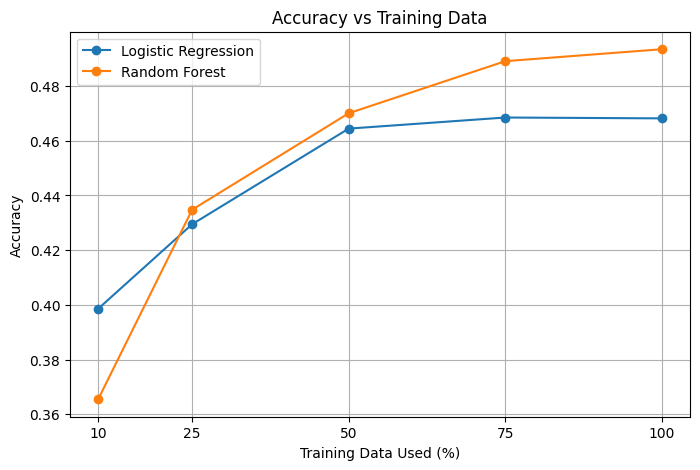

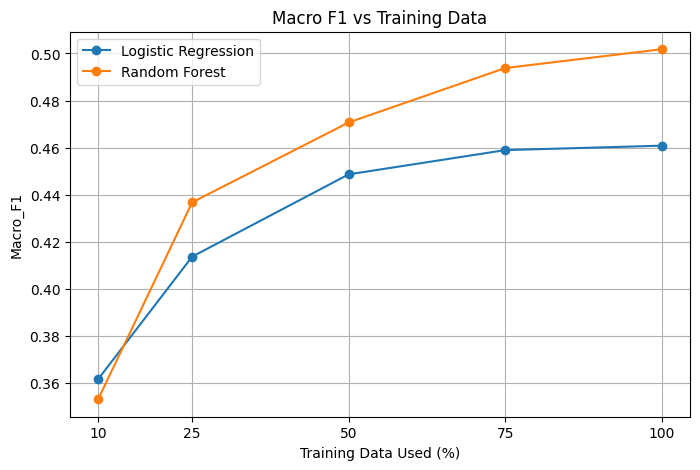

In [33]:
import matplotlib.pyplot as plt

for metric, title in [
    ("Accuracy_Mean", "Accuracy vs Training Data"),
    ("Macro_F1_Mean", "Macro F1 vs Training Data")
]:
    plt.figure(figsize=(8, 5))

    for model_name in summary_df["Model"].unique():
        data = summary_df[
            summary_df["Model"] == model_name
        ].sort_values("Fraction")

        plt.plot(
            data["Fraction"] * 100,
            data[metric],
            marker="o",
            label=model_name
        )

    plt.xlabel("Training Data Used (%)")
    plt.ylabel(metric.replace("_Mean", ""))
    plt.title(title)
    plt.xticks([10, 25, 50, 75, 100])
    plt.grid(True)
    plt.legend()
    plt.show()

In [34]:
experiment_df.to_csv(
    "/content/data/data_efficiency_individual_results.csv",
    index=False
)

summary_df.to_csv(
    "/content/data/data_efficiency_summary.csv",
    index=False
)

print("Experiment results saved successfully!")

Experiment results saved successfully!


## 11. Discussion and Limitations

### Main findings
- Performance generally improves as more labelled training data is used.
- Random Forest achieves the strongest mean Accuracy and Macro F1 at 100% training data in the data-efficiency experiment.
- At 10% training data, Logistic Regression has slightly higher mean Accuracy, while Random Forest has higher mean Macro F1.
- Geometry-distance features improved the enhanced-model results compared with the movement-only results in the reported comparison.

### Limitations
- The project uses pre-annotated pose coordinates rather than training a pose-estimation model from raw video.
- The anatomical ordering of annotation columns has not been verified; geometry features are therefore exploratory.
- One sequence with no usable movement observations is excluded.
- Only three random seeds are used, so results are preliminary.
- The reported accuracy is moderate; further feature engineering, model tuning, and additional repetitions may be useful.


## 12. Conclusion

This project examined human action recognition using movement and exploratory pose-geometry features from Penn Action annotations. Logistic Regression and Random Forest were evaluated using a fixed official test set and multiple training-data fractions. The results indicate that additional labelled training data generally improves performance, with Random Forest showing the strongest overall results in the data-efficiency experiment. The findings provide a preliminary investigation of data efficiency for pose-based human action recognition.
